# 01 Setup and baselines
## EDA on the training portion only
The test rows are never looked at: they would start to influence our choices. EDA informs decisions, it does not change the data. Any clipping or transform goes inside the `Pipeline`, fit on training folds only.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.lib import RESULTS_DIR, load_data, load_split
from src.utils import load_config, set_seed

cfg = load_config()
set_seed(cfg["seed"])

X, y = load_data()
df = X.join(y)
target = y.name  # MedHouseVal, in units of $100k

_test_idx, folds = load_split()  # the test indices are not used in this notebook
train = df.iloc[np.sort(np.concatenate([val for _, val in folds]))]
print("training rows:", len(train), "of", len(df))

training rows: 16512 of 20640


### 1. The basics

In [2]:
print("shape:", train.shape)
print("\ncolumn types:")
print(train.dtypes)
print("\nmissing values:", int(train.isna().sum().sum()))
print("duplicate rows:", int(train.duplicated().sum()))
train.describe().T

shape: (16512, 9)

column types:
MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object

missing values: 0
duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
MedInc,16512.0,3.880754,1.904294,0.499900,2.566700,3.545800,4.773175,15.000100
HouseAge,16512.0,28.608285,12.602499,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,16512.0,5.435235,2.387375,0.888889,4.452055,5.235874,6.061037,141.909091
AveBedrms,16512.0,1.096685,0.433215,0.333333,1.006508,1.049286,1.100348,25.636364
Population,16512.0,1426.453004,1137.056380,3.000000,789.000000,1167.000000,1726.000000,35682.000000
AveOccup,16512.0,3.096961,11.578744,0.692308,2.428799,2.817240,3.280000,1243.333333
Latitude,16512.0,35.643149,2.136665,32.550000,33.930000,34.260000,37.720000,41.950000
Longitude,16512.0,-119.582290,2.005654,-124.350000,-121.810000,-118.510000,-118.010000,-114.310000
MedHouseVal,16512.0,2.071947,1.156226,0.149990,1.198000,1.798500,2.651250,5.000010


### 2. The target

rows at the cap (>= 5.0): 808 (4.9%)


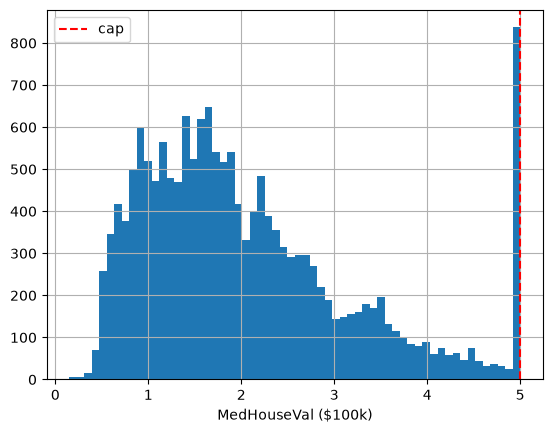

In [3]:
CAP = 5.0
at_cap = (train[target] >= CAP).sum()
print(f"rows at the cap (>= {CAP}): {at_cap} ({at_cap / len(train):.1%})")

ax = train[target].hist(bins=60)
ax.axvline(CAP, color="red", ls="--", label="cap")
ax.set_xlabel("MedHouseVal ($100k)")
ax.legend()
plt.show()

### 3. The features

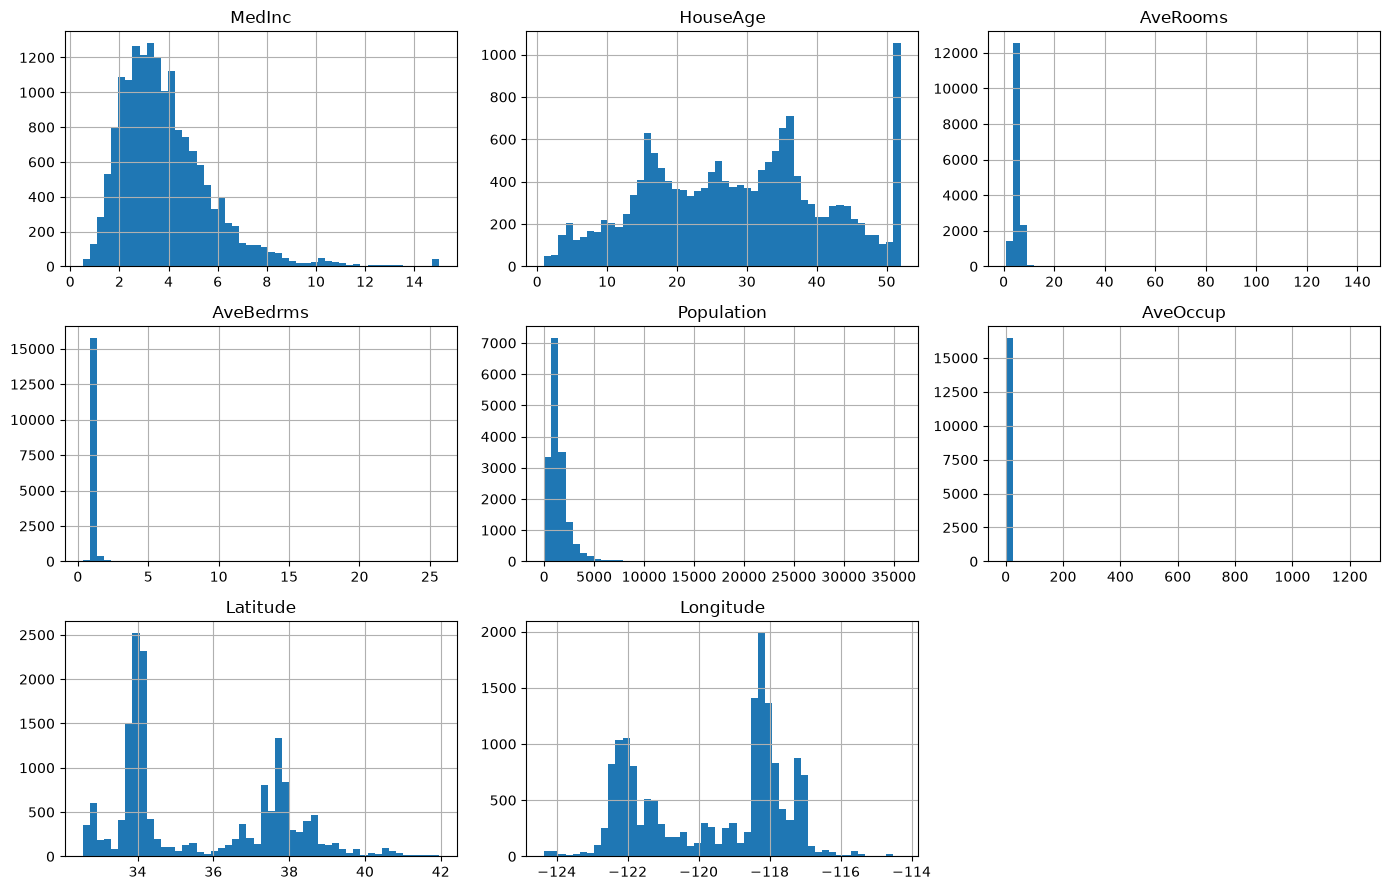

skew:
MedInc         1.63
HouseAge       0.06
AveRooms      18.61
AveBedrms     23.17
Population     5.28
AveOccup      88.05
Latitude       0.46
Longitude     -0.29
dtype: float64

rows with HouseAge == 52: 1023
rows with MedInc >= 15: 43


,AveRooms,AveBedrms,AveOccup,Population
0.50,5.235874,1.049286,2.817240,1167.00
0.99,10.318432,2.116536,5.410157,5798.72
1.00,141.909091,25.636364,1243.333333,35682.00


In [4]:
features = X.columns
train[features].hist(bins=50, figsize=(14, 9))
plt.tight_layout()
plt.show()

print("skew:")
print(train[features].skew().round(2))
print("\nrows with HouseAge == 52:", int((train["HouseAge"] == 52).sum()))
print("rows with MedInc >= 15:", int((train["MedInc"] >= 15).sum()))
train[["AveRooms", "AveBedrms", "AveOccup", "Population"]].quantile([0.5, 0.99, 1.0])

### 4. Relationships

            spearman  pearson
AveOccup      -0.258   -0.022
Latitude      -0.163   -0.143
AveBedrms     -0.130   -0.051
Longitude     -0.072   -0.046
Population     0.004   -0.026
HouseAge       0.072    0.104
AveRooms       0.261    0.158
MedInc         0.678    0.691


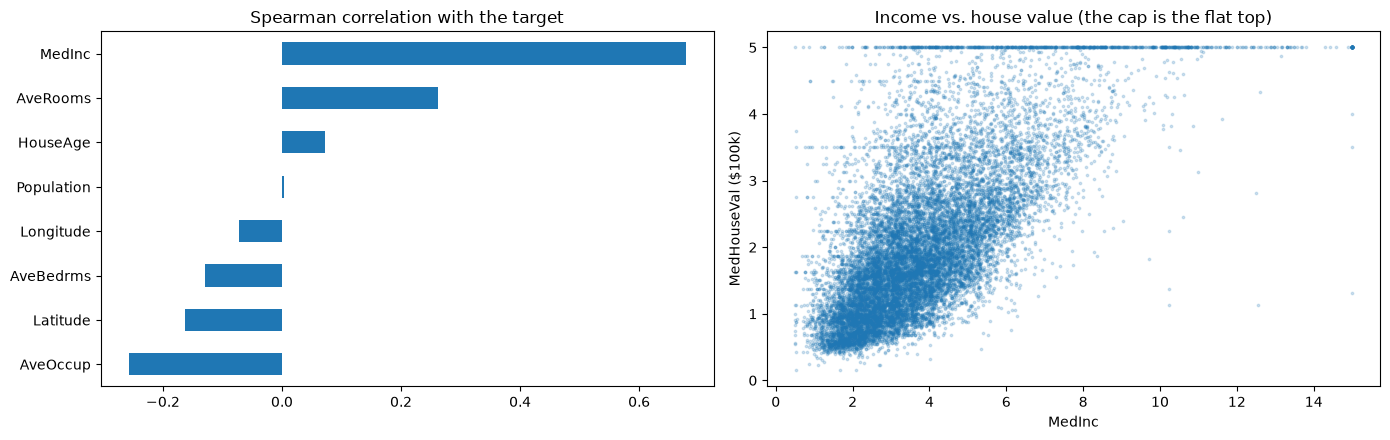

In [5]:
spearman = train.corr(method="spearman")[target].drop(target).sort_values()
pearson = train.corr()[target].drop(target)
print(pd.DataFrame({"spearman": spearman, "pearson": pearson[spearman.index]}).round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
spearman.plot.barh(ax=axes[0])
axes[0].set_title("Spearman correlation with the target")
axes[1].scatter(train["MedInc"], train[target], s=3, alpha=0.2)
axes[1].set_xlabel("MedInc")
axes[1].set_ylabel("MedHouseVal ($100k)")
axes[1].set_title("Income vs. house value (the cap is the flat top)")
plt.tight_layout()
plt.show()

### 5. Geography

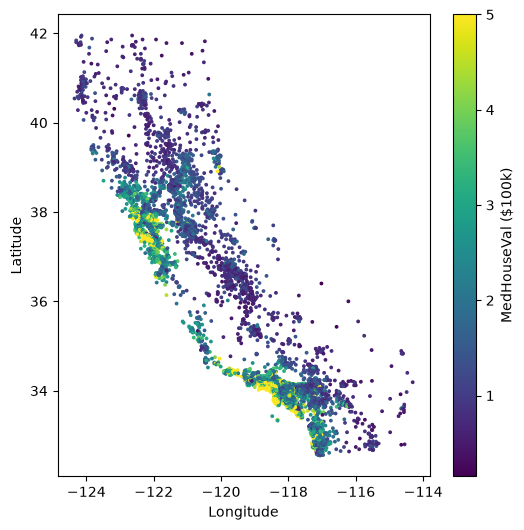

In [6]:
plt.figure(figsize=(6, 6))
sc = plt.scatter(train["Longitude"], train["Latitude"], c=train[target], s=3, cmap="viridis")
plt.colorbar(sc, label="MedHouseVal ($100k)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

### 6. Findings
1. **The target is capped.** 808 training rows (4.9%) sit at $500k, and their real value is higher. This puts a ceiling on how good any model can look at the top end. Report the error on capped rows separately later.
2. **Some features have extreme outliers, and the scales differ.** `AveOccup` (skew 88), `AveBedrms` (23) and `AveRooms` (19) have a few absurd rows, for example `AveOccup` max 1243 against a median of 2.8. `Population` is in the thousands while `AveBedrms` is near 1. Trees don't care. Ridge and the MLP need the scaler, and may need clipping, done inside the `Pipeline`.
3. **`HouseAge` and `MedInc` are capped too.** 1,023 rows (6.2%) have `HouseAge` = 52 and 43 rows have `MedInc` >= 15. Read the top of each as "52 or older" and "15 or more".
4. **Income dominates, and outliers hide other signals.** `MedInc` has a Spearman correlation of 0.68. `AveOccup` shows -0.26 by Spearman but -0.02 by Pearson, so its outliers mask a real link. Use rank correlation when reading these.
5. **Geography matters, and a random split is optimistic.** Expensive blocks cluster along the coast (Bay Area, Los Angeles, San Diego) while the inland valleys are cheap. Trees can learn this from `Latitude` and `Longitude`. Neighboring blocks land in both train and test, so scores will look better than they would in a new region.


### Figure 1: price map and target histogram

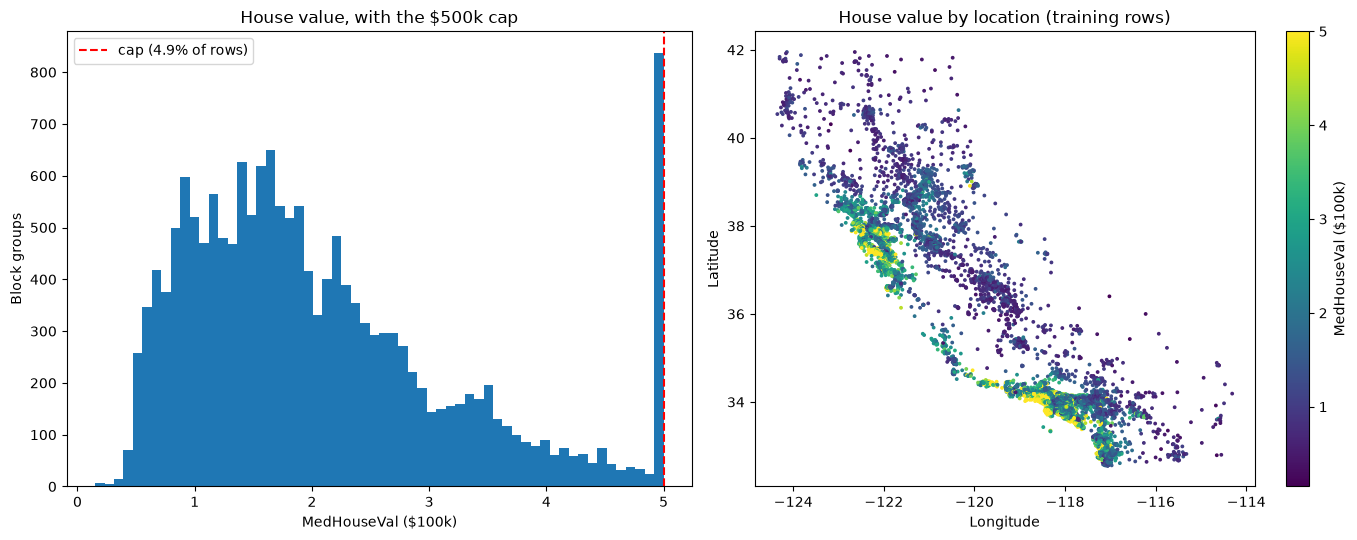

In [7]:
RESULTS_DIR.mkdir(exist_ok=True)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

axes[0].hist(train[target], bins=60)
axes[0].axvline(CAP, color="red", ls="--", label=f"cap ({at_cap / len(train):.1%} of rows)")
axes[0].set_xlabel("MedHouseVal ($100k)")
axes[0].set_ylabel("Block groups")
axes[0].set_title("House value, with the $500k cap")
axes[0].legend()

sc = axes[1].scatter(train["Longitude"], train["Latitude"], c=train[target], s=3, cmap="viridis")
fig.colorbar(sc, ax=axes[1], label="MedHouseVal ($100k)")
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")
axes[1].set_title("House value by location (training rows)")

plt.tight_layout()
fig.savefig(RESULTS_DIR / "fig1_eda.png", dpi=150)
plt.show()

## Baselines
Predict-the-mean, ridge and a single decision tree, scored by the same 5-fold CV that every later model will use. These numbers are the floor: an ensemble is only interesting if it clearly beats them. Folds use the training portion only, so the test set stays untouched.

In [ ]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor

from src.lib import build_pipeline, evaluate_regression

seed = cfg["seed"]
baselines = {
    "mean": build_pipeline(DummyRegressor(strategy="mean"), scale=False),
    "ridge": build_pipeline(Ridge()),
    "tree (depth 6)": build_pipeline(DecisionTreeRegressor(max_depth=6, random_state=seed), scale=False),
}

rows = []
for name, model in baselines.items():
    scores = []
    for train_idx, val_idx in folds:
        model.fit(X.iloc[train_idx], y.iloc[train_idx])
        scores.append(evaluate_regression(y.iloc[val_idx], model.predict(X.iloc[val_idx])))
    scores = pd.DataFrame(scores)
    row = {"model": name}
    for metric in ["rmse", "mae", "r2"]:
        row[f"{metric}_mean"] = scores[metric].mean()
        row[f"{metric}_std"] = scores[metric].std()
    rows.append(row)

table = pd.DataFrame(rows).set_index("model")
RESULTS_DIR.mkdir(exist_ok=True)
table.to_csv(RESULTS_DIR / "baselines.csv")

# readable view: mean ± std across the 5 folds
pd.DataFrame(
    {m.upper(): table[f"{m}_mean"].map("{:.3f}".format) + " ± " + table[f"{m}_std"].map("{:.3f}".format) for m in ["rmse", "mae", "r2"]}
)

**Takeaways** (RMSE in units of $100k, mean ± std over 5 folds)
- **Predict-the-mean:** RMSE 1.156 ± 0.014, R² about 0. This is the floor, and it equals the target's spread.
- **Ridge:** RMSE 0.721 ± 0.016, R² 0.61. A straight-line fit on 8 features already explains about 61% of the variance.
- **Decision tree (depth 6, fixed, not tuned):** RMSE 0.693 ± 0.015, R² 0.64. It is the best of the three.
- **The tree beats ridge by only 0.03 RMSE, about 2x the fold std.** That is a modest edge, so don't over-read it. The strongest baseline for later comparisons is the tree at 0.693.
